In [5]:
#import required classes and packages
from lightgbm import LGBMClassifier
from web3 import Web3, HTTPProvider
import json
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import SGDClassifier
from sklearn.linear_model import PassiveAggressiveClassifier
import pandas as pd #pandas to read and explore dataset
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import timeit
from sklearn.linear_model import Perceptron
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt   

In [6]:
#function to initialize Blockchain contract to save and get local models
def getContract():
    blockchain_address = 'http://127.0.0.1:9545'
    web3 = Web3(HTTPProvider(blockchain_address))
    web3.eth.defaultAccount = web3.eth.accounts[0]
    compiled_contract_path = 'MLContract.json' #Smart Contract to manage ML model weights
    deployed_contract_address = '0x2E7DdC8D59004571Ca8165Cd77e591df4eD94aDA' #contract address
    with open(compiled_contract_path) as file:
        contract_json = json.load(file)  # load contract info as JSON
        contract_abi = contract_json['abi']  # fetch contract's abi - necessary to call its functions
    file.close()
    contract = web3.eth.contract(address=deployed_contract_address, abi=contract_abi)
    return contract, web3
contract, web3 = getContract()
print("Blockchain Contract Deployment & Connection Successful")

Blockchain Contract Deployment & Connection Successful


In [7]:
#function to get list of weights from Blockchain for all clients
def getWeightList():
    global contract
    weightList = []
    count = contract.functions.getModelCount().call()
    for i in range(0, count):
        model_name = contract.functions.getClientName(i).call()
        model_weight = contract.functions.getWeight(i).call()
        model_intercept = contract.functions.getHash(i).call()
        model_classes = contract.functions.getDate(i).call()
        weightList.append([model_name, model_weight, model_intercept, model_intercept])
    return weightList            
weightList = getWeightList()    
print("Blockchain Model Weight List Initialized")

MismatchedABI: ("The function 'getClientName' was not found in this contract's abi. ", 'Are you sure you provided the correct contract abi?')

In [8]:
#loading and displaying IoT23 attack dataset
dataset = pd.read_csv("Dataset/data.csv")
dataset

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
1,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
2,1,TRANSFER,2806.00,C1420196421,2806.00,0.00,C972765878,0.00,0.00,1,0
3,1,CASH_OUT,2806.00,C2101527076,2806.00,0.00,C1007251739,26202.00,0.00,1,0
4,1,TRANSFER,20128.00,C137533655,20128.00,0.00,C1848415041,0.00,0.00,1,0
...,...,...,...,...,...,...,...,...,...,...,...
28208,8,CASH_IN,141811.33,C1507170630,2596606.93,2738418.25,C746359178,742685.98,1793011.10,0,0
28209,8,CASH_IN,632085.47,C1414128792,2738418.25,3370503.73,C264685626,1736548.55,0.00,0,0
28210,8,CASH_IN,150605.27,C1540927,3370503.73,3521109.00,C75629578,1075492.86,707849.71,0,0
28211,8,CASH_IN,53634.28,C1781243086,3521109.00,3574743.28,C464246030,352529.81,0.00,0,0


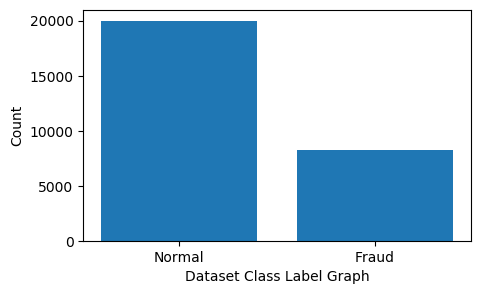

In [9]:
#visualizing different attack class labels count found in dataset
names, count = np.unique(dataset['isFraud'], return_counts = True)
labels = ['Normal', 'Fraud']
height = count
bars = labels
y_pos = np.arange(len(bars))
plt.figure(figsize = (5, 3)) 
plt.bar(y_pos, height)
plt.xticks(y_pos, bars)
plt.xlabel("Dataset Class Label Graph")
plt.ylabel("Count")
plt.show()

In [10]:
#applying dataset processing technique to convert non-numeric data to numeric data
label_encoder = []
columns = dataset.columns
types = dataset.dtypes.values
for j in range(len(types)):
    name = types[j]
    if name == 'object': #finding column with object type
        le = LabelEncoder()
        dataset[columns[j]] = pd.Series(le.fit_transform(dataset[columns[j]].astype(str)))#encode all str columns to numeric
        label_encoder.append([columns[j], le])
Y = dataset['isFraud'].ravel()
dataset.drop(['isFraud'], axis = 1,inplace=True)
dataset.fillna(dataset.mean(), inplace = True)#replace misisng values with mean
dataset

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFlaggedFraud
0,1,4,181.00,4425,181.00,0.00,8104,0.00,0.00,0
1,1,1,181.00,25850,181.00,0.00,7216,21182.00,0.00,0
2,1,4,2806.00,6052,2806.00,0.00,10356,0.00,0.00,0
3,1,1,2806.00,16162,2806.00,0.00,41,26202.00,0.00,0
4,1,4,20128.00,5404,20128.00,0.00,4627,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...
28208,8,0,141811.33,7337,2596606.93,2738418.25,9152,742685.98,1793011.10,0
28209,8,0,632085.47,5960,2738418.25,3370503.73,6541,1736548.55,0.00,0
28210,8,0,150605.27,7891,3370503.73,3521109.00,9208,1075492.86,707849.71,0
28211,8,0,53634.28,11444,3521109.00,3574743.28,7619,352529.81,0.00,0


In [11]:
#dataset shuffling & Normalization
X = dataset.values
scaler = StandardScaler()
X = scaler.fit_transform(X)#normalize dataset values
indices = np.arange(X.shape[0])
np.random.shuffle(indices)#shuffle dataset values
X = X[indices]
Y = Y[indices]
print("Dataset shuffling & Normalization Completed")

Dataset shuffling & Normalization Completed


In [12]:
#applying smote algorithm to handle imbalance data
print("Total records available in dataset before applying SMOTE = "+str(X.shape[0]))
smote = SMOTE()
X, Y = smote.fit_resample(X, Y)
print("Total records available in dataset after applying SMOTE = "+str(X.shape[0]))

Total records available in dataset before applying SMOTE = 28213
Total records available in dataset after applying SMOTE = 40000


In [13]:
#now dividing dataset into different difficulty levels to calculate training time where difficulty 1 will be 
#containing 10000 records and difficulty level 2 contains 30000 records
diff_1_X = X[0:10000]
diff_1_Y = Y[0:10000]
diff_2_X = X[10000:X.shape[0]]
diff_2_Y = Y[10000:X.shape[0]]
print("Difficulty Levels Created")

Difficulty Levels Created


In [14]:
#define global variables to save accuracy and other metrics
accuracy = []
precision = []
recall = []
fscore = []
mining_time = []

In [15]:
#function to calculate all algorithms metrics like accuracy, precision etc
def calculateMetrics(algorithm, predict, y_test, run_time):
    a = accuracy_score(y_test,predict)*100
    p = precision_score(y_test, predict,average='macro') * 100
    r = recall_score(y_test, predict,average='macro') * 100
    f = f1_score(y_test, predict,average='macro') * 100
    accuracy.append(a)
    precision.append(p)
    recall.append(r)
    fscore.append(f)
    mining_time.append(run_time)
    print(algorithm+" Accuracy  :  "+str(a))
    print(algorithm+" Precision : "+str(p))
    print(algorithm+" Recall    : "+str(r))
    print(algorithm+" FScore    : "+str(f)) 
    print(algorithm+" Mining Time : "+str(run_time))
    conf_matrix = confusion_matrix(y_test, predict) 
    plt.figure(figsize =(6, 3)) 
    ax = sns.heatmap(conf_matrix, xticklabels = labels, yticklabels = labels, annot = True, cmap="viridis" ,fmt ="g");
    ax.set_ylim([0,len(labels)])
    plt.title(algorithm+" Confusion matrix") 
    plt.ylabel('True class') 
    plt.xlabel('Predicted class') 
    plt.show()  

In [16]:
#function to train all algorithms increment and then report best model to Blockchain
def trainIncrement(algorithm, algorithm_name, XX, YY, initial, weights, intercept, classes):
    X_train, X_test, y_train, y_test = train_test_split(XX, YY, test_size = 0.2)#split data to train and test
    start = timeit.default_timer()
    if initial == False:  #if model already trained then set old weights to trained incrementally
        algorithm.coef_ = weights
        algorithm.intercept_ = intercept
        algorithm.classes_ = classes
    algorithm.partial_fit(X_train, y_train, np.unique(YY))#train on new data and incrment model updates
    predict = algorithm.predict(X_test)#perfrom prediction on test data
    weights = algorithm.coef_   #obtained model weights
    intercept = algorithm.intercept_
    classes_details = algorithm.classes_
    end = timeit.default_timer()
    run_time = end - start
    calculateMetrics(algorithm_name, predict, y_test, run_time)#call function to calculate accuracy and other metrics
    return weights, intercept, classes_details

PAC Initial Accuracy  :  98.8
PAC Initial Precision : 99.16839916839916
PAC Initial Recall    : 97.93459552495698
PAC Initial FScore    : 98.52623124168703
PAC Initial Mining Time : 0.004916300000004981


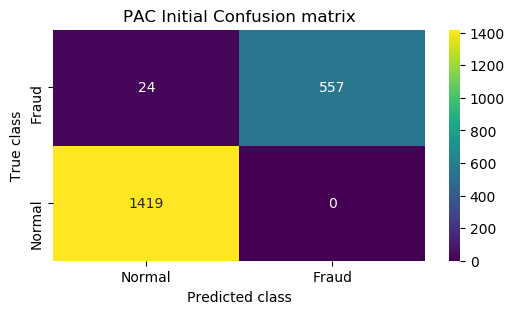

In [17]:
#train PAC as initial run with difficulty1
pac = PassiveAggressiveClassifier(warm_start=True)
pac_initial_weights, pac_initial_intercept, pac_initial_classes = trainIncrement(pac, "PAC Initial", diff_1_X, diff_1_Y, True, None, None, None)

PAC Increment Accuracy  :  99.03333333333333
PAC Increment Precision : 98.9388568959333
PAC Increment Recall    : 99.09980540100891
PAC Increment FScore    : 99.01556883544396
PAC Increment Mining Time : 0.01149130000000298


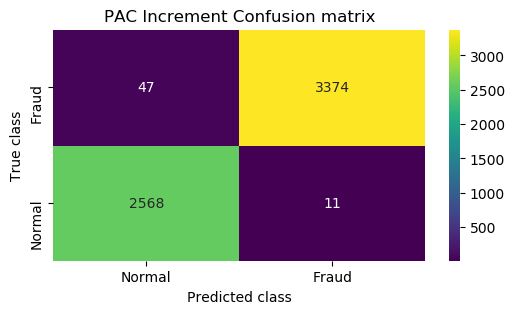

In [18]:
#train pac with increment learning using difficulty level2
pac_increment_weights, pac_increment_intercept, pac_increment_classes = trainIncrement(pac, "PAC Increment", diff_2_X, diff_2_Y, False,
                                                     pac_initial_weights, pac_initial_intercept, pac_initial_classes)


SGD Initial Accuracy  :  96.2
SGD Initial Precision : 94.5368059374574
SGD Initial Recall    : 96.49858913016807
SGD Initial FScore    : 95.44110872235872
SGD Initial Mining Time : 0.004200000000011528


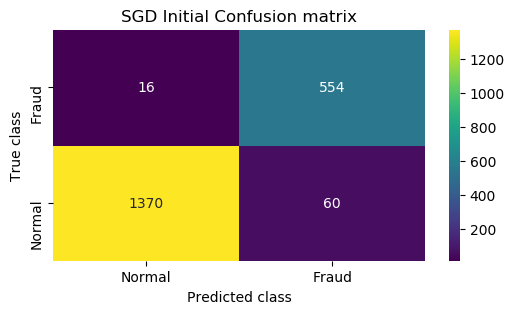

In [19]:
#train SGD as initial run with difficulty1
sgd = SGDClassifier(warm_start=True)
sgd_initial_weights, sgd_initial_intercept, sgd_initial_classes = trainIncrement(sgd, "SGD Initial", diff_1_X, diff_1_Y, True, None, None, None)

SGD Increment Accuracy  :  98.83333333333333
SGD Increment Precision : 98.68735174996472
SGD Increment Recall    : 98.96285568803874
SGD Increment FScore    : 98.81327772691826
SGD Increment Mining Time : 0.01152859999999123


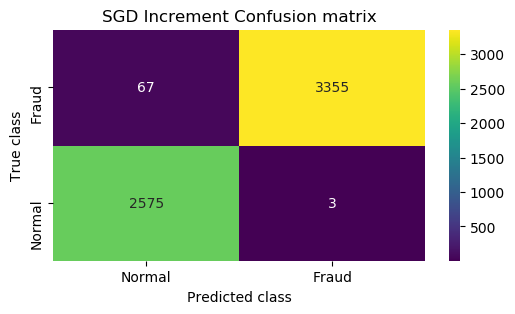

In [20]:
#train SGD with increment learning using difficulty level2
sgd_increment_weights, sgd_increment_intercept, sgd_increment_classes = trainIncrement(sgd, "SGD Increment", diff_2_X, diff_2_Y, False,
                                                     sgd_initial_weights, sgd_initial_intercept, sgd_initial_classes)


Perceptron Initial Accuracy  :  98.3
Perceptron Initial Precision : 98.82189882189883
Perceptron Initial Recall    : 97.12351945854483
Perceptron Initial FScore    : 97.9230908317899
Perceptron Initial Mining Time : 0.006443200000006755


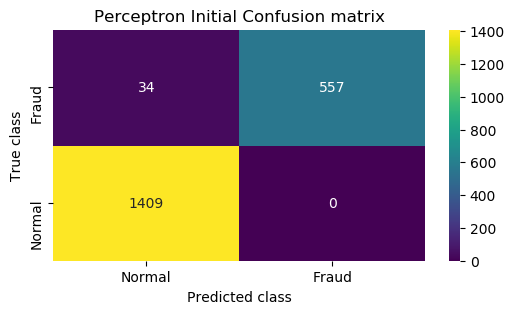

In [21]:
#train Perceptron as initial run with difficulty1
perceptron = Perceptron(warm_start=True)
per_initial_weights, per_initial_intercept, per_initial_classes = trainIncrement(perceptron, "Perceptron Initial", diff_1_X, diff_1_Y, True, None, None, None)

Perceptron Increment Accuracy  :  98.31666666666666
Perceptron Increment Precision : 98.27257170084299
Perceptron Increment Recall    : 98.26713087694564
Perceptron Increment FScore    : 98.26984832993683
Perceptron Increment Mining Time : 0.014116799999996488


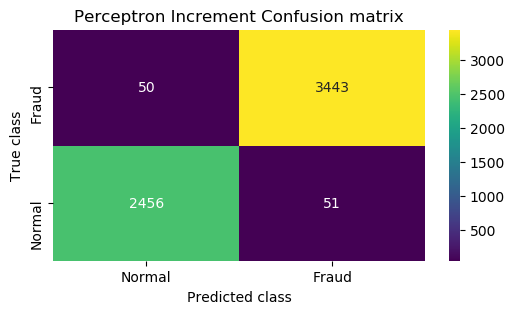

In [22]:
#train Perceptron with increment learning using difficulty level2
per_increment_weights, per_increment_intercept, per_increment_classes = trainIncrement(perceptron, "Perceptron Increment", diff_2_X, diff_2_Y, False,
                                                     per_initial_weights, per_initial_intercept, per_initial_classes)


BernoulliNB Accuracy  :  93.55
BernoulliNB Precision : 92.68534633423906
BernoulliNB Recall    : 91.80327673319051
BernoulliNB FScore    : 92.22745245716438
BernoulliNB Mining Time : 0.005299700000009011


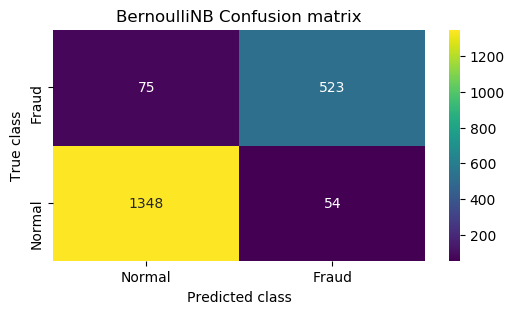

In [23]:
#train naive bayes as initial run with difficulty1
bnb = BernoulliNB()
bnb_initial_weights, bnb_initial_intercept, bnb_initial_classes = trainIncrement(bnb, "BernoulliNB", diff_1_X, diff_1_Y, True, None, None, None)

BernoulliNB Increment Accuracy  :  92.71666666666667
BernoulliNB Increment Precision : 92.46837101606555
BernoulliNB Increment Recall    : 93.13135758998435
BernoulliNB Increment FScore    : 92.64868146868578
BernoulliNB Increment Mining Time : 0.019031099999992307


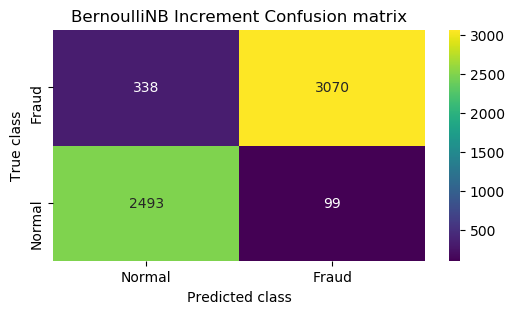

In [24]:
#train naive bayes with increment learning using difficulty level2
bnb_increment_weights, bnb_increment_intercept, bnb_increment_classes = trainIncrement(bnb, "BernoulliNB Increment", diff_2_X, diff_2_Y, True,
                                                     bnb_initial_weights, bnb_initial_intercept, bnb_initial_classes)

In [25]:
#function to train lightGBM algorithm
def trainLGBMIncrement(algorithm, algorithm_name, XX, YY):
    X_train, X_test, y_train, y_test = train_test_split(XX, YY, test_size = 0.2)#split data to train and test
    start = timeit.default_timer()
    algorithm.fit(X_train, y_train)
    predict = algorithm.predict(X_test)
    end = timeit.default_timer()
    run_time = end - start
    calculateMetrics(algorithm_name, predict, y_test, run_time)#call function to calculate accuracy and other metrics    

C:\Users\Gandla shivasai\AppData\Roaming\Python\Python37\site-packages\joblib\externals\loky\backend\context.py:137: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  "Could not find the number of physical cores for the "
  File "C:\Users\Gandla shivasai\AppData\Roaming\Python\Python37\site-packages\joblib\externals\loky\backend\context.py", line 260, in _count_physical_cores
    text=True,
  File "c:\users\gandla shivasai\appdata\local\programs\python\python37\lib\subprocess.py", line 453, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\users\gandla shivasai\appdata\local\programs\python\python37\lib\subprocess.py", line 756, in __init__
    restore_signals, start_new_session)
  File "c:\users\gandla shivasai\appdata\local\programs\py

[LightGBM] [Info] Number of positive: 2354, number of negative: 5646
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000979 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2045
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.294250 -> initscore=-0.874831
[LightGBM] [Info] Start training from score -0.874831
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
LightGBM Initial Accuracy  :  99.8
LightGBM Initial Precision : 99.85994397759103
LightGBM Initial Recall    : 99.65277777777779
LightGBM Initial FScore    : 99.75565774491646
LightGBM Initial Mining Time : 

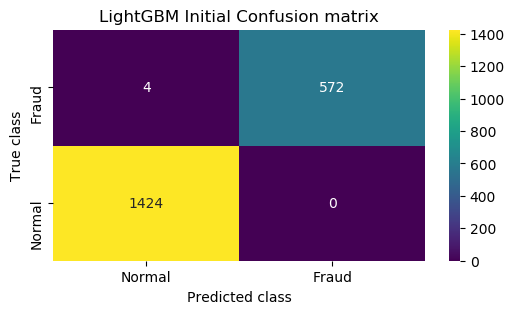

In [26]:
#train lightGBM as initial run with difficulty1
lgbm_cls = LGBMClassifier()
trainLGBMIncrement(lgbm_cls, "LightGBM Initial", diff_1_X, diff_1_Y)

[LightGBM] [Info] Number of positive: 13623, number of negative: 10377
[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002694 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2049
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.567625 -> initscore=0.272168
[LightGBM] [Info] Start training from score 0.272168
LightGBM Increment Accuracy  :  99.88333333333334
LightGBM Increment Precision : 99.86819443756676
LightGBM Increment Recall    : 99.89338299589178
LightGBM Increment FScore    : 99.880714618273
LightGBM Increment Mining Time : 1.2324978999999985


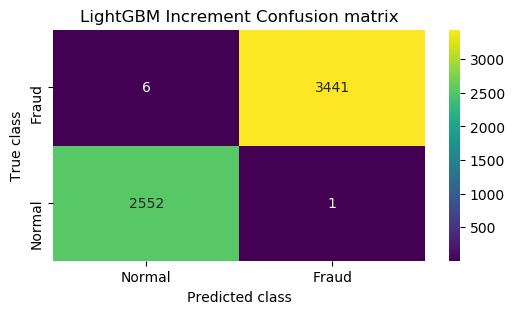

In [27]:
#train lightGBM  with increment learning using difficulty level2
trainLGBMIncrement(lgbm_cls, "LightGBM Increment", diff_2_X, diff_2_Y)

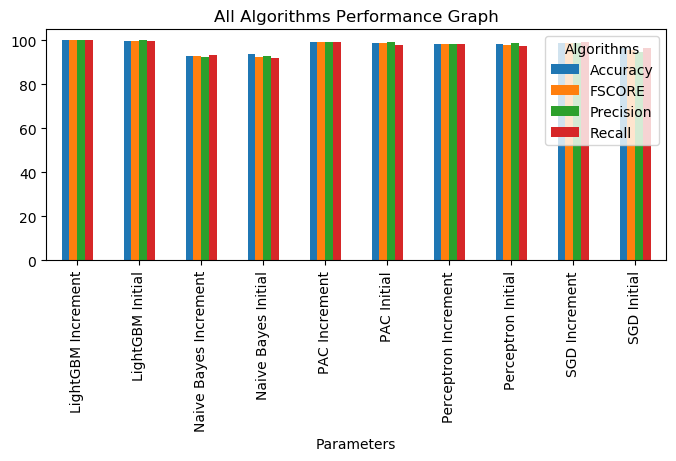

In [28]:
#plot all algorithm performance in tabukar format
df = pd.DataFrame([['PAC Initial','Accuracy',accuracy[0]],['PAC Initial','Precision',precision[0]],['PAC Initial','Recall',recall[0]],['PAC Initial','FSCORE',fscore[0]],
                   ['PAC Increment','Accuracy',accuracy[1]],['PAC Increment','Precision',precision[1]],['PAC Increment','Recall',recall[1]],['PAC Increment','FSCORE',fscore[1]],
                   ['SGD Initial','Accuracy',accuracy[2]],['SGD Initial','Precision',precision[2]],['SGD Initial','Recall',recall[2]],['SGD Initial','FSCORE',fscore[2]],
                   ['SGD Increment','Accuracy',accuracy[3]],['SGD Increment','Precision',precision[3]],['SGD Increment','Recall',recall[3]],['SGD Increment','FSCORE',fscore[3]],
                   ['Perceptron Initial','Accuracy',accuracy[4]],['Perceptron Initial','Precision',precision[4]],['Perceptron Initial','Recall',recall[4]],['Perceptron Initial','FSCORE',fscore[4]],
                   ['Perceptron Increment','Accuracy',accuracy[5]],['Perceptron Increment','Precision',precision[5]],['Perceptron Increment','Recall',recall[5]],['Perceptron Increment','FSCORE',fscore[5]],
                   ['Naive Bayes Initial','Accuracy',accuracy[6]],['Naive Bayes Initial','Precision',precision[6]],['Naive Bayes Initial','Recall',recall[6]],['Naive Bayes Initial','FSCORE',fscore[6]],
                   ['Naive Bayes Increment','Accuracy',accuracy[7]],['Naive Bayes Increment','Precision',precision[7]],['Naive Bayes Increment','Recall',recall[7]],['Naive Bayes Increment','FSCORE',fscore[7]],
                   ['LightGBM Initial','Accuracy',accuracy[8]],['LightGBM Initial','Precision',precision[8]],['LightGBM Initial','Recall',recall[8]],['LightGBM Initial','FSCORE',fscore[8]],
                   ['LightGBM Increment','Accuracy',accuracy[9]],['LightGBM Increment','Precision',precision[9]],['LightGBM Increment','Recall',recall[9]],['LightGBM Increment','FSCORE',fscore[9]],
                  ],columns=['Parameters','Algorithms','Value'])
df.pivot("Parameters", "Algorithms", "Value").plot(kind='bar', figsize=(8, 3))
plt.title("All Algorithms Performance Graph")
plt.show()

In [29]:
#display all algorithm performnace
algorithms = ['PAC Initial', 'PAC Increment', 'SGD Initial', 'SGD Increment', 'Perceptron Initial', 'Perceptron Increment',
             'Naive Bayes Initial', 'Naive Bayes Increment', 'LightGBM Initail', 'LightGBM Increment']
data = []
for i in range(len(accuracy)):
    data.append([algorithms[i], accuracy[i], precision[i], recall[i], fscore[i]])
data = pd.DataFrame(data, columns=['Algorithm Name', 'Accuracy', 'Precision', 'Recall', 'FSCORE'])
data  

,Algorithm Name,Accuracy,Precision,Recall,FSCORE
0,PAC Initial,98.800000,99.168399,97.934596,98.526231
1,PAC Increment,99.033333,98.938857,99.099805,99.015569
2,SGD Initial,96.200000,94.536806,96.498589,95.441109
3,SGD Increment,98.833333,98.687352,98.962856,98.813278
4,Perceptron Initial,98.300000,98.821899,97.123519,97.923091
5,Perceptron Increment,98.316667,98.272572,98.267131,98.269848
6,Naive Bayes Initial,93.550000,92.685346,91.803277,92.227452
7,Naive Bayes Increment,92.716667,92.468371,93.131358,92.648681
8,LightGBM Initail,99.800000,99.859944,99.652778,99.755658
9,LightGBM Increment,99.883333,99.868194,99.893383,99.880715


In [30]:
def getWeightsData(value):
    return " ".join(str(x) for x in value)

In [31]:
if len(weightList) == 0:
    bcfl_1 = contract.functions.saveBestModel("SGD Increment", getWeightsData(sgd_increment_weights),
                                              getWeightsData(sgd_increment_intercept), getWeightsData(sgd_increment_classes)).transact()
    weightList.append(["SGD Increment", getWeightsData(sgd_increment_weights),
                       getWeightsData(sgd_increment_intercept), getWeightsData(sgd_increment_classes)])
    bc2_receipt = web3.eth.waitForTransactionReceipt(bcfl_1)    #saving weight to blockchain
else:
    bcf1_1 = contract.functions.updateWeight(0, getWeightsData(sgd_increment_weights)).transact()
    bcfl_1 = contract.functions.updateHashcode(0, getWeightsData(sgd_increment_intercept)).transact()
    bcfl_1 = contract.functions.updateDate(0, getWeightsData(sgd_increment_classes)).transact()
    bc2_receipt = web3.eth.waitForTransactionReceipt(bcfl_1)#updating weight to blockchain
print("Blockchain Log After Storing Best Model Weights\n"+str(bc2_receipt)+"\n")   

NameError: name 'weightList' is not defined

In [32]:
#import flask library
from flask import Flask, render_template, request, redirect, url_for, session,send_from_directory

In [33]:
app = Flask(__name__)
app.secret_key = 'welcome'

In [34]:
@app.route('/Predict', methods=['GET', 'POST'])
def predictView():
    return render_template('Predict.html', msg='')

@app.route('/index', methods=['GET', 'POST'])
def index():
    return render_template('index.html', msg='')

@app.route('/AdminLogin', methods=['GET', 'POST'])
def AdminLogin():
    return render_template('AdminLogin.html', msg='')

@app.route('/AdminLoginAction', methods=['GET', 'POST'])
def AdminLoginAction():
    if request.method == 'POST' and 't1' in request.form and 't2' in request.form:
        user = request.form['t1']
        password = request.form['t2']
        if user == "admin" and password == "admin":
            return render_template('AdminScreen.html', msg="Welcome "+user)
        else:
            return render_template('AdminLogin.html', msg="Invalid login details")

@app.route('/Logout')
def Logout():
    return render_template('index.html', msg='')

@app.route('/PredictAction', methods=['GET', 'POST'])
def PredictAction():
    if request.method == 'POST':
        #create sgd classifier by getting weights from Blockchain
        sgd = SGDClassifier(warm_start=True)
        sgd.coef_ = sgd_increment_weights
        sgd.intercept_ = sgd_increment_intercept
        sgd.classes_ = sgd_increment_classes
        #loading test data file then applying blockchain model to predict fraud
        testData = pd.read_csv("Dataset/testData.csv")
        temp = testData.values
        for i in range(len(label_encoder)): #loop each object column and convert to numeric format
            le = label_encoder[i]
            testData[le[0]] = pd.Series(le[1].transform(testData[le[0]].astype(str)))#encode all str columns to numeric
        testData.fillna(dataset.mean(), inplace = True) 
        testData = testData.values
        testData = scaler.transform(testData)
        predict = sgd.predict(testData)
        output = ""
        for i in range(len(predict)):
            if predict[i] == 0:
                output += "Test Data = "+str(temp[i])+" <font size=3 color=green>Predicted Transaction ===> "+str(labels[predict[i]])+"</font><br/><br/>"
            else:
                output += "Test Data = "+str(temp[i])+" <font size=3 color=red>Predicted Transaction ===> "+str(labels[predict[i]])+"</font><br/><br/>"
        return render_template('AdminScreen.html', msg=output)


In [ ]:
if __name__ == '__main__':
    app.run()  

 * Serving Flask app '__main__' (lazy loading)
 * Environment: production
   Use a production WSGI server instead.
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit
127.0.0.1 - - [27/Oct/2026 15:06:45] "GET / HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:01] "GET / HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:09] "GET /index.html HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:10] "GET /index.html HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:13] "GET /index.html HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:14] "GET /index.html HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:07:53] "GET /adminscreen.html HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /index HTTP/1.1" 200 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /static/images/tra.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /static/default.css HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /static/images/back.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /static/images/img02.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:09:12] "GET /static/images/img01.jpg HTTP/1.1" 4

127.0.0.1 - - [27/Oct/2026 15:14:58] "GET /static/images/img01.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:14:58] "GET /static/images/img03.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:14:58] "GET /static/images/img023.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:16:25] "GET / HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /index HTTP/1.1" 200 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/default.css HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/tra.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/back.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/img02.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/img01.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/img023.jpg HTTP/1.1" 304 -
127.0.0.1 - - [27/Oct/2026 15:16:35] "GET /static/images/img03.jpg HTTP/1.1" 404 -
127.0.0.1 - - [27/Oct/2026 15:16:36] "GET /AdminLog